# Factorial designs, and what a fraction gives up

Five factors, each at a low and a high setting. Running every combination takes $2^5 = 32$ runs,
and those 32 runs estimate 31 effects: five main effects, ten two-factor interactions, and sixteen
interactions of three or more factors that are usually too small to matter. A **fractional
factorial** runs a half or a quarter of the combinations and spends exactly those unlikely
high-order effects to buy the runs back.

This notebook builds the full factorial by hand and reads its effects. Then it keeps 16 of the runs,
then 8, and shows what each fraction can and cannot tell apart. It closes with **center points**,
the cheap check for curvature that no corner run can see.

The data are synthetic, generated from a true model that the package states, so you can check what
each design recovers. Every fraction below is a subset of the same 32 runs, so any difference
between designs comes from the design and not from fresh noise.

**Where this fits.** `planning_an_experiment.ipynb`, in this folder, is the short path: how many
runs, what to cut first, how to build on runs you already have. This notebook is the long version of
three of its steps. The main effects show why every run counts toward every effect (step 2, hidden
replication). The fractions show what the third and fourth rungs of the reduction ladder give up
(step 3). The center points and the fold-over question are the standard follow-ups (steps 3 and 6).
If you only need the basics, read the planning notebook first and come back here for the why.

## Setup: where the package lives

This notebook builds its designs by hand and then checks them against `orteach`, the package in
`src/`. Run from a clone of the repository, `../../src` is right there. On Colab there is no clone
until this cell makes one, and no `gurobipy` until it installs it. Nothing here needs a secret.

In [1]:
import os, subprocess, sys

REPO_URL = "https://github.com/sear-labs/teaching-code"
REF = "v1.0.1"                               # the release this notebook ships in: Colab clones THIS

try:
    import google.colab                      # noqa: F401 - succeeds only on Colab
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

if ON_COLAB:
    if not os.path.isdir("/content/teaching-code"):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "--branch", REF, REPO_URL, "/content/teaching-code"], check=True)
    os.chdir("/content/teaching-code/notebooks/15_design_of_experiments")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "gurobipy>=11,<14"], check=True)

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "src")))
try:
    import orteach                            # noqa: F401
except ImportError:
    raise SystemExit("orteach not found: run this notebook from its own folder inside the repository, "
                     "so that ../../src exists.")
root = os.path.abspath(os.path.join("..", ".."))
print("package:", os.path.relpath(os.path.dirname(orteach.__file__), root))

package: src\orteach


## The runs are a table

A reactor with five factors, each coded $-1$ for its low setting and $+1$ for its high one: A
temperature, B catalyst, C time, D stirring, E feed rate. The table holds all 32 combinations in
**standard order**, where A alternates fastest. It also holds the **run order**, the randomized
order the runs were made in. Randomizing spreads slow drifts, such as a warming room or an ageing
catalyst batch, across all the settings instead of piling them onto one factor. Four more runs sit
at the **center**, every factor at its middle setting; they wait until the last section.

The package generated the table from a printed seed and stores it in `data/raw/`, so this notebook
and the package read the same file.

In [2]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from orteach import doe
from orteach.tolerance import AGREEMENT_RTOL, rel_diff

runs = doe.load_reactor()
print("generated from seed", doe.REACTOR_SEED)
print("factors:", doe.FACTOR_NAMES)

# Split the table: the 32 corner runs, and the 4 runs at the center
is_corner = np.array(runs["kind"]) == "factorial"
all_yields = np.array(runs["yield"])
X = np.column_stack([np.array(runs[f])[is_corner] for f in "ABCDE"]).astype(float)   # one row per corner run
y = all_yields[is_corner]                    # yield at each corner, in standard order
y_center = all_yields[~is_corner]            # yield at the four center runs
run_order = np.array(runs["run_order"])[is_corner]   # the order the corners were actually made in

print(f"\n{len(y)} corner runs and {len(y_center)} center runs. The first eight corners:")
print(" A B C D E   run order   yield")
for i in range(8):
    signs = " ".join("+" if x > 0 else "-" for x in X[i])
    print(f" {signs}   {run_order[i]:9d}   {y[i]:5.2f}")

# to try different data, edit a yield here; the change reaches the package check at the bottom:
# y[5] = 70.0

generated from seed 20261118
factors: {'A': 'temperature', 'B': 'catalyst', 'C': 'time', 'D': 'stirring', 'E': 'feed rate'}

32 corner runs and 4 center runs. The first eight corners:
 A B C D E   run order   yield
 - - - - -           4   48.64
 + - - - -          21   57.75
 - + - - -          27   54.59
 + + - - -          34   73.40
 - - + - -           9   47.25
 + - + - -          23   53.64
 - + + - -          30   49.30
 + + + - -          35   66.33


## The full factorial: every corner, once

Build the design yourself. `itertools.product((-1, 1), repeat=5)` lists every sign pattern with the
*last* factor alternating fastest; reversing each row with `row[::-1]` puts A first, which is
standard order.

Two properties make a factorial worth running, and both can be printed. **Balance**: every column
has as many $+1$s as $-1$s, so each column sums to zero. **Orthogonality**: every pair of columns
is uncorrelated, so $X^\top X$ is diagonal. Orthogonality means each effect is estimated as if the
others were not there.

In [3]:
# Every sign pattern of five factors, each row reversed so that A alternates fastest
design = np.array([row[::-1] for row in itertools.product((-1, 1), repeat=5)], dtype=float)
print("runs in a 2^5 full factorial:", len(design))
print("same rows, same order as the table:", bool((design == X).all()))
print("column sums:", design.sum(axis=0).astype(int))
print("X'X =")
print((design.T @ design).astype(int))

runs in a 2^5 full factorial: 32
same rows, same order as the table: True
column sums: [0 0 0 0 0]
X'X =
[[32  0  0  0  0]
 [ 0 32  0  0  0]
 [ 0  0 32  0  0]
 [ 0  0  0 32  0]
 [ 0  0  0  0 32]]


## Main effects

The **main effect** of a factor is the mean response at its high setting minus the mean response at
its low setting. Each one uses all 32 runs, 16 against 16. That is the quiet efficiency of a
factorial: every run informs every effect, where changing one factor at a time would spend separate
runs on each. This is the hidden replication that lets step 2 of the planning notebook count total
runs instead of replicates.

Before running this, look at the eight rows printed above and write down which factor you predict
matters most, and whether any will come out near zero.

In [4]:
# Main effect = mean yield at the high setting - mean yield at the low setting
main = {}
for j, f in enumerate("ABCDE"):
    mean_high = y[X[:, j] > 0].mean()        # the 16 runs with this factor at +1
    mean_low = y[X[:, j] < 0].mean()         # the 16 runs with it at -1
    main[f] = mean_high - mean_low
    print(f"{f} {doe.FACTOR_NAMES[f]:12} mean at +1 {mean_high:6.2f}   at -1 {mean_low:6.2f}   effect {main[f]:+6.2f}")

A temperature  mean at +1  62.42   at -1  50.72   effect +11.69
B catalyst     mean at +1  60.65   at -1  52.49   effect  +8.16
C time         mean at +1  53.97   at -1  59.17   effect  -5.19
D stirring     mean at +1  56.86   at -1  56.27   effect  +0.59
E feed rate    mean at +1  56.80   at -1  56.34   effect  +0.47


### The main-effects plot

The same ten means, drawn. A steep line is a large effect; a flat one is a factor that does little
over the range tested. All five panels share one vertical scale, so the slopes can be compared
directly.

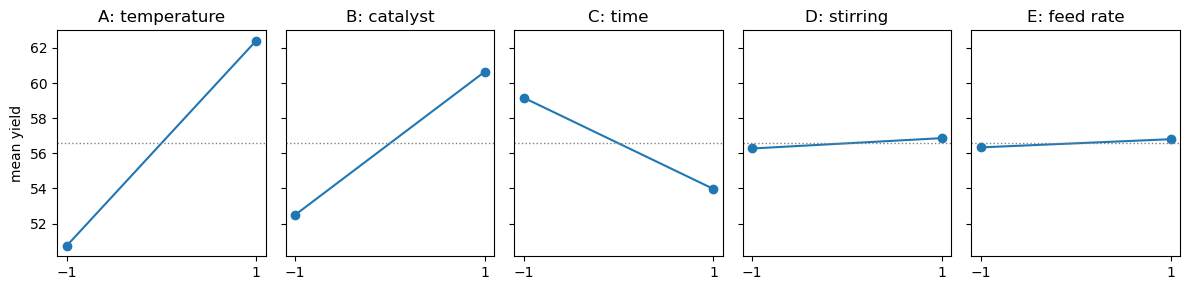

Figure: five panels, each joining the mean yield at a factor's low and high setting. A (temperature) has the steepest line, a change of +11.69; E (feed rate) is nearly flat at +0.47. The dotted line in each panel is the grand mean, 56.57.


In [5]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3), sharey=True)
for j, (f, ax) in enumerate(zip("ABCDE", axes)):
    mean_low, mean_high = y[X[:, j] < 0].mean(), y[X[:, j] > 0].mean()
    ax.plot([-1, 1], [mean_low, mean_high], "o-", color="tab:blue")
    ax.axhline(y.mean(), color="gray", ls=":", lw=1)       # the grand mean
    ax.set_xticks([-1, 1])
    ax.set_title(f"{f}: {doe.FACTOR_NAMES[f]}")
axes[0].set_ylabel("mean yield")
plt.tight_layout()
plt.show()

steep = max(main, key=lambda f: abs(main[f]))              # the largest effect
flat = min(main, key=lambda f: abs(main[f]))               # the smallest
print(f"Figure: five panels, each joining the mean yield at a factor's low and high setting. "
      f"{steep} ({doe.FACTOR_NAMES[steep]}) has the steepest line, a change of {main[steep]:+.2f}; "
      f"{flat} ({doe.FACTOR_NAMES[flat]}) is nearly flat at {main[flat]:+.2f}. "
      f"The dotted line in each panel is the grand mean, {y.mean():.2f}.")

## Interactions

Two factors **interact** when the effect of one depends on the setting of the other. The AB column
is the elementwise product of the A and B columns: $+1$ where A and B are at the same setting, $-1$
where they differ. Its effect is computed exactly like a main effect.

The same number has a second reading, and this cell computes both: half the difference between A's
effect when B is high and A's effect when B is low.

In [6]:
# Reading 1: the AB column is A times B; its effect is computed like any main effect
AB = X[:, 0] * X[:, 1]
ab_effect = y[AB > 0].mean() - y[AB < 0].mean()

# Reading 2: A's effect among the runs with B high, and among the runs with B low
A_high, A_low = X[:, 0] > 0, X[:, 0] < 0
B_high, B_low = X[:, 1] > 0, X[:, 1] < 0
a_when_b_high = y[A_high & B_high].mean() - y[A_low & B_high].mean()
a_when_b_low = y[A_high & B_low].mean() - y[A_low & B_low].mean()
print(f"effect of A when B is high {a_when_b_high:+.2f}, when B is low {a_when_b_low:+.2f}")
print(f"half their difference      {(a_when_b_high - a_when_b_low) / 2:+.2f}")
print(f"AB effect from its column  {ab_effect:+.2f}")

effect of A when B is high +17.50, when B is low +5.88
half their difference      +5.81
AB effect from its column  +5.81


### The interaction plot

Plot mean yield against A, with one line for each setting of the second factor. Parallel lines mean
no interaction: A does the same thing whatever the other factor is doing. Lines that fan apart or
cross mean the effect of A depends on it.

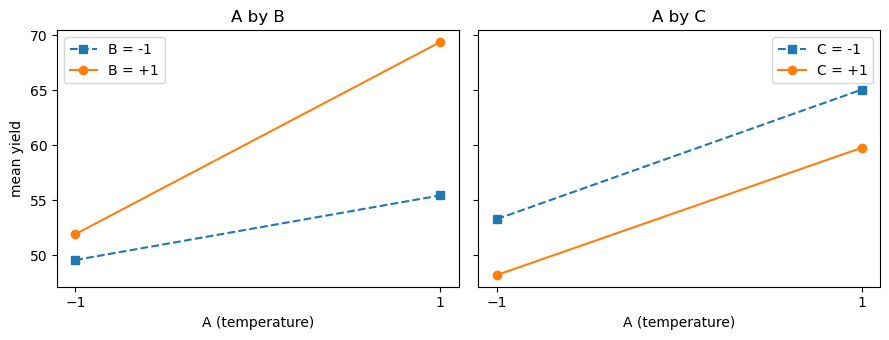

Figure: two interaction plots of mean yield against A. Left, one line per setting of B: the lines fan apart, because A's effect is +17.50 with B high and +5.88 with B low (AB effect +5.81). Right, one line per setting of C: the lines are close to parallel (AC effect -0.10). Solid lines with circles mark the high setting, dashed lines with squares the low.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, k, name in zip(axes, (1, 2), ("B", "C")):           # the second factor: B, then C
    for level, style in ((-1, "s--"), (1, "o-")):           # one line per setting of it
        at_level = X[:, k] == level
        means = [y[at_level & A_low].mean(), y[at_level & A_high].mean()]
        ax.plot([-1, 1], means, style, label=f"{name} = {level:+d}")
    ax.set_xticks([-1, 1])
    ax.set_xlabel("A (temperature)")
    ax.set_title(f"A by {name}")
    ax.legend()
axes[0].set_ylabel("mean yield")
plt.tight_layout()
plt.show()

AC = X[:, 0] * X[:, 2]
ac_effect = y[AC > 0].mean() - y[AC < 0].mean()
print(f"Figure: two interaction plots of mean yield against A. Left, one line per setting of B: the "
      f"lines fan apart, because A's effect is {a_when_b_high:+.2f} with B high and {a_when_b_low:+.2f} "
      f"with B low (AB effect {ab_effect:+.2f}). Right, one line per setting of C: the lines are close "
      f"to parallel (AC effect {ac_effect:+.2f}). Solid lines with circles mark the high setting, "
      f"dashed lines with squares the low.")

## All thirty-one effects

Every subset of the five letters is an effect: 5 main effects, 10 two-factor interactions, 10
three-factor, 5 four-factor and 1 five-factor. Each one's column is the product of its factors'
columns. Thirty-two runs give 32 numbers, and here they are spent on the grand mean and 31 effects,
with nothing left over to estimate the noise. The next cell lists the largest.

In [8]:
# Every subset of ABCDE, smallest first: "A", ..., "AB", ..., "ABCDE"
words = ["".join(c) for size in range(1, 6) for c in itertools.combinations("ABCDE", size)]

cols, effect = {}, {}
for w in words:
    factor_cols = ["ABCDE".index(f) for f in w]
    cols[w] = np.prod(X[:, factor_cols], axis=1)            # the product of its factors' columns
    effect[w] = y[cols[w] > 0].mean() - y[cols[w] < 0].mean()

per_order = {size: sum(len(w) == size for w in words) for size in range(1, 6)}
print(len(words), "effects; how many of each order:", per_order)

ranked = sorted(words, key=lambda w: -abs(effect[w]))      # largest first
for w in ranked[:8]:
    print(f"  {w:5} {effect[w]:+6.2f}")
print("  ...")
print(f"  smallest: {ranked[-1]} {effect[ranked[-1]]:+.2f}")

31 effects; how many of each order: {1: 5, 2: 10, 3: 10, 4: 5, 5: 1}
  A     +11.69
  B      +8.16
  AB     +5.81
  C      -5.19
  ABDE   -1.68
  ACD    +1.44
  BC     -1.16
  ABCD   -0.94
  ...
  smallest: CDE -0.02


### Which effects are real? The half-normal plot

With no replicates there is no separate estimate of noise, so borrow one from the effects
themselves. If most effects are pure noise, their absolute values behave like draws from a
half-normal distribution: sorted and plotted against half-normal quantiles, they fall along a line
through the origin. A real effect sits off to the right of that line.

**Lenth's method** (1989) makes "off the line" a number. Take $s_0 = 1.5 \times$ the median
absolute effect, drop every effect larger than $2.5\,s_0$, and call $1.5 \times$ the median of what
is left the pseudo standard error (PSE). The margin of error (ME) is a $t$ quantile times the PSE;
the simultaneous margin (SME) is wider, because it allows for looking at 31 effects at once.

Predict how many effects will clear each margin before you run it.

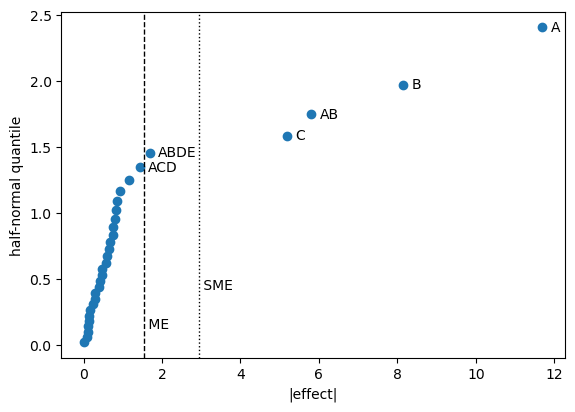

PSE 0.698   ME 1.549   SME 2.946
Figure: the 31 absolute effects against half-normal quantiles. Most lie on a steep line near the origin; 5 lie to the right of the dashed ME line (A, B, AB, C, ABDE) and 4 to the right of the dotted SME line (A, B, AB, C).


In [9]:
# The 31 absolute effects, smallest first, and the half-normal quantile each is plotted against
abs_sorted = np.sort(np.abs([effect[w] for w in words]))
smallest_first = sorted(words, key=lambda w: abs(effect[w]))
hn_quantile = stats.norm.ppf(0.5 + 0.5 * (np.arange(1, 32) - 0.5) / 31)

# Lenth's method: a noise estimate from the effects themselves
s0 = 1.5 * np.median(abs_sorted)
pse = 1.5 * np.median(abs_sorted[abs_sorted < 2.5 * s0])    # pseudo standard error
me = stats.t.ppf(0.975, 31 / 3) * pse                        # margin of error, one effect at a time
sme = stats.t.ppf((1 + 0.95 ** (1 / 31)) / 2, 31 / 3) * pse  # simultaneous margin, all 31 at once

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(abs_sorted, hn_quantile, "o", color="tab:blue")
for w, a, q in zip(smallest_first[-6:], abs_sorted[-6:], hn_quantile[-6:]):   # label the six largest
    ax.annotate(w, (a, q), textcoords="offset points", xytext=(6, -3))
ax.axvline(me, color="black", ls="--", lw=1)
ax.text(me, 0.1, " ME", va="bottom")
ax.axvline(sme, color="black", ls=":", lw=1)
ax.text(sme, 0.4, " SME", va="bottom")
ax.set_xlabel("|effect|")
ax.set_ylabel("half-normal quantile")
plt.show()

past_me = [w for w in ranked if abs(effect[w]) > me]
past_sme = [w for w in ranked if abs(effect[w]) > sme]
print(f"PSE {pse:.3f}   ME {me:.3f}   SME {sme:.3f}")
print(f"Figure: the 31 absolute effects against half-normal quantiles. Most lie on a steep line near "
      f"the origin; {len(past_me)} lie to the right of the dashed ME line ({', '.join(past_me)}) and "
      f"{len(past_sme)} to the right of the dotted SME line ({', '.join(past_sme)}).")

Some effects clear the ME line but not the SME line. Would you report a four-factor interaction as
a finding? What would you want to see before you believed one?

## Effects are regression coefficients, doubled

The same analysis as a regression: fit yield on an intercept and the columns you believe in, by the
normal equations $M^\top M \beta = M^\top y$. Predict A's coefficient from its effect before you run
this. A coefficient is the change per one coded unit, and $-1$ to $+1$ is two units.

In [10]:
terms = ["A", "B", "C", "D", "E", "AB"]                   # the columns we believe in
M = np.column_stack([np.ones(len(y))] + [cols[w] for w in terms])   # intercept, then one column per term
beta = np.linalg.solve(M.T @ M, M.T @ y)                    # the normal equations
print(f"{'term':10} {'coefficient':>12} {'effect / 2':>12}")
print(f"{'intercept':10} {beta[0]:12.4f}   (the mean of all 32 runs is {y.mean():.4f})")
for w, b in zip(terms, beta[1:]):
    print(f"{w:10} {b:12.4f} {effect[w] / 2:12.4f}")

term        coefficient   effect / 2
intercept       56.5691   (the mean of all 32 runs is 56.5691)
A                5.8466       5.8466
B                4.0778       4.0778
C               -2.5972      -2.5972
D                0.2953       0.2953
E                0.2328       0.2328
AB               2.9053       2.9053


---

## A half fraction: sixteen runs

Most of those 31 effects were noise. A half fraction runs 16 of the 32 combinations, chosen so that
the effects you care about stay separable. This is the third rung of the planning notebook's
reduction ladder; there it is priced in power, and here in what it can no longer tell apart. Choose it by **setting E not freely, but equal to the
product ABCD**. That one choice has a price: in the 16 runs, the E column and the ABCD column are
identical, so E and ABCD cannot be told apart. They are **aliases**.

Every alias follows from one identity. If $E = ABCD$ then multiplying both sides by E gives
$I = ABCDE$, where $I$ is a column of ones, because any letter times itself is 1. This is the
**defining relation**. Multiply any effect by it to find its alias: $A \cdot ABCDE = BCDE$, and
$AB \cdot ABCDE = CDE$. The length of the shortest word in the defining relation is the design's
**resolution**: here 5, so main effects are aliased only with four-factor interactions and
two-factor interactions only with three-factor ones.

Five dimensions cannot be drawn, so start with three. The picture below is the half fraction of a
$2^3$ with $C = AB$, drawn on the cube of A, B and C; each corner is labelled with the mean yield of
the reactor runs at that corner.

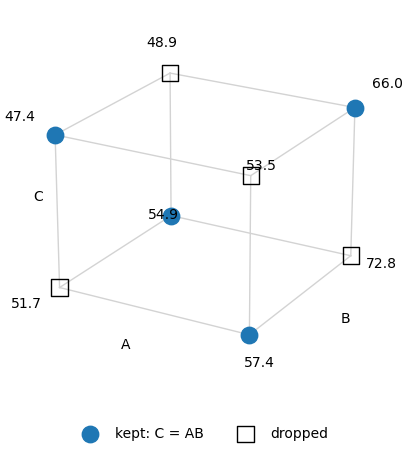

Figure: a cube with axes A, B and C. The 4 filled circles are the corners where C = AB, the 4 open squares the corners dropped. Kept corners sharing an edge: 0. Each corner is labelled with its mean yield, from 47.4 to 72.8. Viewed down any axis, the kept corners still cover all four combinations of the other two factors.


In [11]:
# The 8 corners of the A-B-C cube; the half fraction keeps those where C = AB
corners = np.array([row[::-1] for row in itertools.product((-1, 1), repeat=3)])
kept = corners[:, 2] == corners[:, 0] * corners[:, 1]
# Label each corner with the mean yield of the reactor runs there (averaging over D and E)
avg = [y[(X[:, 0] == a) & (X[:, 1] == b) & (X[:, 2] == c)].mean() for a, b, c in corners]

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
for p1, p2 in itertools.combinations(corners, 2):
    if np.abs(p1 - p2).sum() == 2:                          # two corners that share an edge
        ax.plot(*zip(p1, p2), color="lightgray", lw=1)
ax.scatter(*corners[kept].T, s=140, color="tab:blue", marker="o", depthshade=False, label="kept: C = AB")
ax.scatter(*corners[~kept].T, s=140, facecolors="none", edgecolors="black", marker="s",
           depthshade=False, label="dropped")
for (a, b, c), value in zip(corners, avg):
    ax.text(a * 1.22, b * 1.22, c * 1.22, f"{value:.1f}", fontsize=10, ha="center")
ax.text(0, -1.45, -1.25, "A", ha="center")
ax.text(1.45, 0, -1.25, "B", ha="center")
ax.text(-1, -1, 0.15, "C   ", ha="right")
ax.set_axis_off()
ax.view_init(elev=22, azim=-60)
fig.legend(loc="lower center", ncol=2, frameon=False)
plt.show()
shared_edge = sum(np.abs(p1 - p2).sum() == 2 for p1, p2 in itertools.combinations(corners[kept], 2))
print(f"Figure: a cube with axes A, B and C. The {kept.sum()} filled circles are the corners where C = AB, "
      f"the {(~kept).sum()} open squares the corners dropped. Kept corners sharing an edge: {shared_edge}. "
      f"Each corner is labelled with its mean yield, from {min(avg):.1f} to {max(avg):.1f}. Viewed down any "
      f"axis, the kept corners still cover all four combinations of the other two factors.")

Every other corner, and no two kept corners share an edge. Viewed down any axis, the four kept
corners still form a full $2^2$ in the other two factors. That projection property is why a
fraction can still estimate main effects.

Now the real thing. One line selects the 16 runs of the $2^{5-1}$ in which E equals ABCD. Check
that the smaller design is still balanced and orthogonal.

In [12]:
half = X[:, 4] == X[:, 0] * X[:, 1] * X[:, 2] * X[:, 3]        # E = ABCD: this line IS the design
X_half, y_half = X[half], y[half]                                # the 16 runs it keeps
print("runs kept:", half.sum(), "of", len(y))
print("column sums:", X_half.sum(axis=0).astype(int))
print("X'X =")
print((X_half.T @ X_half).astype(int))

runs kept: 16 of 32
column sums: [0 0 0 0 0]
X'X =
[[16  0  0  0  0]
 [ 0 16  0  0  0]
 [ 0  0 16  0  0]
 [ 0  0  0 16  0]
 [ 0  0  0  0 16]]


Estimate the five main effects and ten two-factor interactions from the 16 runs, exactly as before,
and set them beside the full factorial's.

In [13]:
low_order = words[:15]                                         # 5 main effects and 10 two-factor interactions
effect_half = {}
print(f"{'':5} {'full (32)':>10} {'half (16)':>10}")
for w in low_order:
    col_half = cols[w][half]                                   # this effect's column, in the 16 runs
    effect_half[w] = y_half[col_half > 0].mean() - y_half[col_half < 0].mean()
    print(f"{w:5} {effect[w]:+10.2f} {effect_half[w]:+10.2f}")

       full (32)  half (16)
A         +11.69     +11.54
B          +8.16      +8.28
C          -5.19      -6.88
D          +0.59      +0.17
E          +0.47      -0.47
AB         +5.81      +5.79
AC         -0.10      -0.50
AD         -0.14      -0.60
AE         -0.24      +0.62
BC         -1.16      -0.40
BD         -0.76      -1.05
BE         -0.57      +0.86
CD         -0.09      -0.90
CE         -0.66      -0.81
DE         +0.64      +0.36


Close, but not equal. The algebra says why: in the half fraction, each estimate is the sum of an
effect and its alias. Find each alias by brute force, as the column that is identical within the 16
runs, and check the sum against the full factorial's two effects.

In [14]:
# An alias of w: any other effect whose column is identical to w's within the 16 runs
partners_half = {}
for w in low_order:
    partners_half[w] = [v for v in words if v != w and (cols[v][half] == cols[w][half]).all()]
    alias = partners_half[w][0]
    total = effect[w] + effect[alias]                  # what the half fraction should report
    print(f"{w:3} = {alias:5} full-factorial {w} {effect[w]:+6.2f}  +  {alias} {effect[alias]:+6.2f}  =  "
          f"{total:+6.2f}   half says {effect_half[w]:+6.2f}")

A   = BCDE  full-factorial A +11.69  +  BCDE  -0.16  =  +11.54   half says +11.54
B   = ACDE  full-factorial B  +8.16  +  ACDE  +0.12  =   +8.28   half says  +8.28
C   = ABDE  full-factorial C  -5.19  +  ABDE  -1.68  =   -6.88   half says  -6.88
D   = ABCE  full-factorial D  +0.59  +  ABCE  -0.42  =   +0.17   half says  +0.17
E   = ABCD  full-factorial E  +0.47  +  ABCD  -0.94  =   -0.47   half says  -0.47
AB  = CDE   full-factorial AB  +5.81  +  CDE  -0.02  =   +5.79   half says  +5.79
AC  = BDE   full-factorial AC  -0.10  +  BDE  -0.40  =   -0.50   half says  -0.50
AD  = BCE   full-factorial AD  -0.14  +  BCE  -0.46  =   -0.60   half says  -0.60
AE  = BCD   full-factorial AE  -0.24  +  BCD  +0.86  =   +0.62   half says  +0.62
BC  = ADE   full-factorial BC  -1.16  +  ADE  +0.76  =   -0.40   half says  -0.40
BD  = ACE   full-factorial BD  -0.76  +  ACE  -0.29  =   -1.05   half says  -1.05
BE  = ACD   full-factorial BE  -0.57  +  ACD  +1.44  =   +0.86   half says  +0.86
CD  = ABE   full

One main effect moved more than the others between the two designs. Which high-order effect is it
carrying, and did that effect look real on the half-normal plot?

## A quarter fraction: eight runs

Halve again, to the fourth rung of the ladder, the screening design: set $D = AB$ and $E = AC$. Now two words equal $I$, $ABD$ and $ACE$, and so does their
product, $ABD \cdot ACE = BCDE$ (the A's cancel). The defining relation is $I = ABD = ACE = BCDE$.
Its shortest word has three letters, so this is **resolution III**: main effects are aliased with
two-factor interactions.

The half fraction put D, stirring, near zero. Predict what the quarter fraction will say about D.

In [15]:
quarter = (X[:, 3] == X[:, 0] * X[:, 1]) & (X[:, 4] == X[:, 0] * X[:, 2])   # D = AB and E = AC
X_quarter, y_quarter = X[quarter], y[quarter]                               # the 8 runs it keeps
print("runs kept:", quarter.sum())
print(" A B C D E   yield")
for settings, value in zip(X_quarter, y_quarter):
    signs = " ".join("+" if x > 0 else "-" for x in settings)
    print(f" {signs}   {value:5.2f}")

# Main effects from the 8 runs, the usual way
effect_quarter = {}
for j, f in enumerate("ABCDE"):
    effect_quarter[f] = y_quarter[X_quarter[:, j] > 0].mean() - y_quarter[X_quarter[:, j] < 0].mean()
print("\nmain effects from 8 runs:", "   ".join(f"{f} {v:+.2f}" for f, v in effect_quarter.items()))

runs kept: 8
 A B C D E   yield
 + - - - -   57.75
 - + + - -   49.30
 + + - + -   71.47
 - - + + -   47.49
 - + - - +   55.32
 + - + - +   50.59
 - - - + +   54.10
 + + + + +   64.16

main effects from 8 runs: A +9.44   B +7.58   C -6.77   D +6.06   E -0.46


Find the aliases of each main effect in the eight runs, the same brute-force way.

In [16]:
# Aliases in the 8 runs: every other effect whose column matches this factor's exactly
partners_quarter = {}
for f in "ABCDE":
    partners_quarter[f] = [v for v in words if v != f and (cols[v][quarter] == cols[f][quarter]).all()]
    print(f"{f} = {' = '.join(partners_quarter[f])}")
print(f"\nfull factorial: D {effect['D']:+.2f}, AB {effect['AB']:+.2f}.   "
      f"quarter fraction's 'D': {effect_quarter['D']:+.2f}")

A = BD = CE = ABCDE
B = AD = CDE = ABCE
C = AE = BDE = ABCD
D = AB = BCE = ACDE
E = AC = BCD = ABDE

full factorial: D +0.59, AB +5.81.   quarter fraction's 'D': +6.06


Someone who ran only these eight runs would conclude that stirring matters. What is the smallest set
of extra runs that would let them tell D from AB? (Try flipping every sign in the eight runs and
see what that does to the aliases. Step 6 of the planning notebook does exactly this: the
fold-over.)

### Three designs, side by side

The five main effects from each design, on one chart.

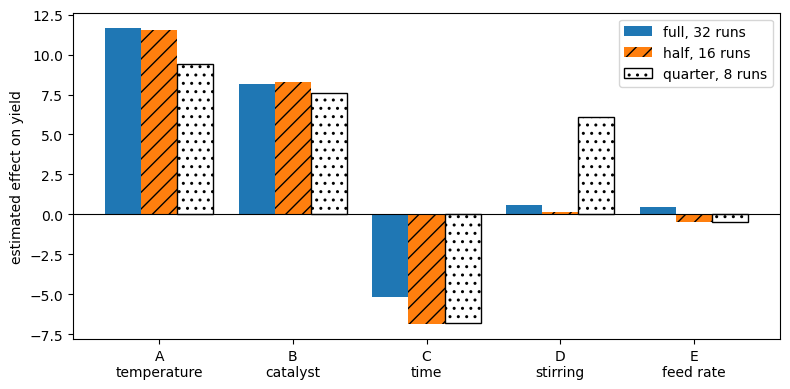

Figure: grouped bars of the five main effects from the full factorial (solid), the half fraction (hatched) and the quarter fraction (dotted). Full and half differ by at most 1.68 on any factor. The quarter fraction's D bar stands at +6.06, where the full factorial's is +0.59.


In [17]:
xs = np.arange(5)
width = 0.27
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(xs - width, [effect[f] for f in "ABCDE"], width, label="full, 32 runs", color="tab:blue")
ax.bar(xs, [effect_half[f] for f in "ABCDE"], width, label="half, 16 runs", color="tab:orange", hatch="//")
ax.bar(xs + width, [effect_quarter[f] for f in "ABCDE"], width, label="quarter, 8 runs",
       color="white", edgecolor="black", hatch="..")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xs, [f"{f}\n{doe.FACTOR_NAMES[f]}" for f in "ABCDE"])
ax.set_ylabel("estimated effect on yield")
ax.legend()
plt.tight_layout()
plt.show()

gap_half = max(abs(effect[f] - effect_half[f]) for f in "ABCDE")   # largest full-vs-half difference
print(f"Figure: grouped bars of the five main effects from the full factorial (solid), the half fraction "
      f"(hatched) and the quarter fraction (dotted). Full and half differ by at most {gap_half:.2f} on any "
      f"factor. The quarter fraction's D bar stands at {effect_quarter['D']:+.2f}, where the full factorial's "
      f"is {effect['D']:+.2f}.")

### The alias map

Another way to see resolution: correlate the 15 low-order columns with each other, within each
design. In the full factorial every pair is uncorrelated. A dark square off the diagonal is a pair of
columns that the design cannot tell apart.

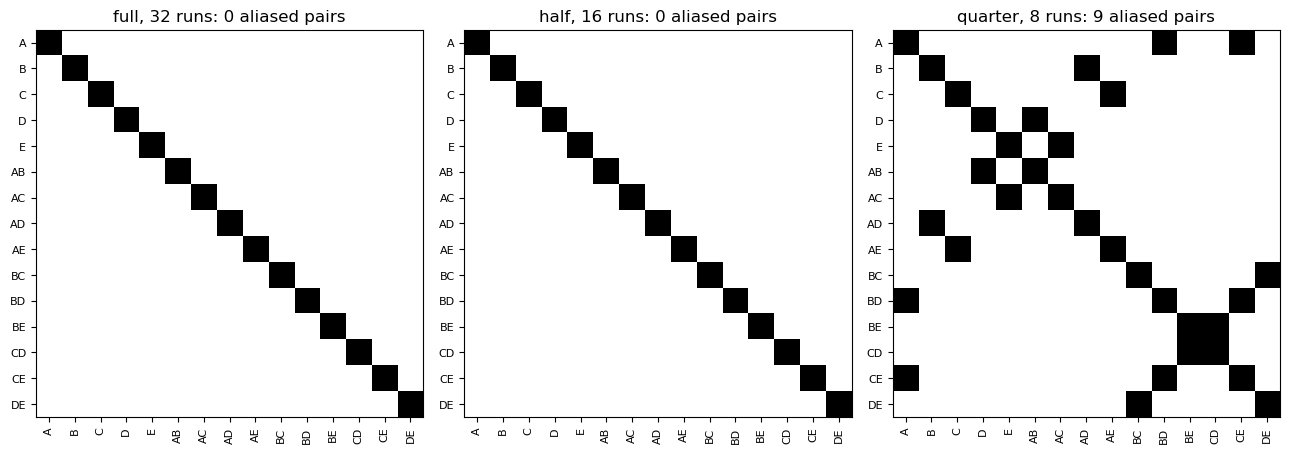

Figure: three 15-by-15 grids of absolute correlation between the main-effect and two-factor columns, black for 1 and white for 0. The full and half designs show only the diagonal (0 and 0 aliased pairs); the quarter fraction shows 9 dark off-diagonal squares, among them D with AB.


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
n_aliased = {}
designs = (("full, 32 runs", np.ones(len(y), dtype=bool)), ("half, 16 runs", half), ("quarter, 8 runs", quarter))
for ax, (name, in_design) in zip(axes, designs):
    # Correlation between every pair of the 15 low-order columns, within this design's runs
    corr = np.corrcoef(np.column_stack([cols[w][in_design] for w in low_order]).T)
    off_diagonal = np.abs(corr - np.eye(15))
    n_aliased[name] = int((off_diagonal > 0.5).sum() // 2)     # each pair appears twice in the grid
    ax.imshow(np.abs(corr), cmap="Greys", vmin=0, vmax=1)
    ax.set_xticks(range(15), low_order, rotation=90, fontsize=8)
    ax.set_yticks(range(15), low_order, fontsize=8)
    ax.set_title(f"{name}: {n_aliased[name]} aliased pairs")
plt.tight_layout()
plt.show()
print(f"Figure: three 15-by-15 grids of absolute correlation between the main-effect and two-factor "
      f"columns, black for 1 and white for 0. The full and half designs show only the diagonal "
      f"({n_aliased['full, 32 runs']} and {n_aliased['half, 16 runs']} aliased pairs); the quarter "
      f"fraction shows {n_aliased['quarter, 8 runs']} dark off-diagonal squares, among them D with AB.")

---

## Center points: is the surface flat?

Every corner run has each factor at $-1$ or $+1$, so a squared term such as $A^2$ equals 1 at
every corner. A curve in A adds the same amount to all 32 runs, and no effect can see it. It only
shifts the mean.

Four runs at the center, every factor at 0, are where a curve shows up. They are what the first rung
of the planning notebook's ladder puts in place of a third level for every factor. If the response were a plane
plus interactions, the center runs would average the same as the corners. Their spread is also the
only **pure error** in the experiment: the same settings run four times, with no model involved.

Predict before you run it: do the center runs sit above, below, or level with the corners?

In [19]:
n_corner, n_center = len(y), len(y_center)
curv = y.mean() - y_center.mean()                 # corners minus centers: zero if the surface is flat

# Is that difference bigger than noise? A t test using the pure error of the center runs
s_pure = y_center.std(ddof=1)                     # pure error: the same settings, run four times
se_curv = s_pure * np.sqrt(1 / n_corner + 1 / n_center)
t_curv = curv / se_curv
p_curv = 2 * stats.t.sf(abs(t_curv), n_center - 1)

print("center runs:", y_center)
print(f"mean of corners {y.mean():.3f}   mean of centers {y_center.mean():.3f}   difference {curv:+.3f}")
print(f"pure-error sd {s_pure:.3f} on {n_center - 1} df   t = {t_curv:.3f}   p = {p_curv:.4f}")

center runs: [60.72 61.72 59.66 59.3 ]
mean of corners 56.569   mean of centers 60.350   difference -3.781
pure-error sd 1.094 on 3 df   t = -6.515   p = 0.0073


Seen as points:

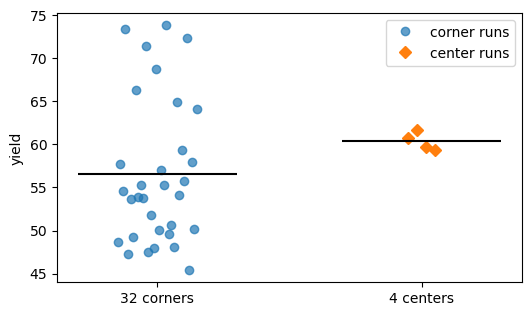

Figure: yields of the 32 corner runs (circles, spread from 45.4 to 73.9) and the 4 center runs (diamonds, from 59.3 to 61.7), each group's mean marked by a black bar: 56.57 for the corners and 60.35 for the centers.


In [20]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.linspace(-0.15, 0.15, n_corner), y, "o", color="tab:blue", alpha=0.7, label="corner runs")
ax.plot(1 + np.linspace(-0.05, 0.05, n_center), y_center, "D", color="tab:orange", label="center runs")
ax.hlines([y.mean(), y_center.mean()], [-0.3, 0.7], [0.3, 1.3], colors="black")   # each group's mean
ax.set_xticks([0, 1], [f"{n_corner} corners", f"{n_center} centers"])
ax.set_ylabel("yield")
ax.legend()
plt.show()
print(f"Figure: yields of the {n_corner} corner runs (circles, spread from {y.min():.1f} to {y.max():.1f}) and "
      f"the {n_center} center runs (diamonds, from {y_center.min():.1f} to {y_center.max():.1f}), each group's "
      f"mean marked by a black bar: {y.mean():.2f} for the corners and {y_center.mean():.2f} for the centers.")

The test says the surface is not flat. Which factor is it curved in? Can four runs at a single point
tell you? Response surface designs answer that by adding runs along each axis; for now, write down
what you would add.

## The answer key

The package states the model that generated the data. Compare it with the full factorial's
regression coefficients, and with the curvature estimate.

In [21]:
print("true model in coded units:", doe.REACTOR_TRUTH, "   noise sd:", doe.REACTOR_SIGMA)
print(f"\n{'term':10} {'true':>8} {'estimated':>10}")
for w, b in zip(["intercept"] + terms, beta):
    print(f"{w:10} {doe.REACTOR_TRUTH.get(w, 0.0):8.2f} {b:10.2f}")
print(f"{'AA':10} {doe.REACTOR_TRUTH['AA']:8.2f} {curv:10.2f}   (from the center points)")

true model in coded units: {'intercept': 60.0, 'A': 6.0, 'B': 4.0, 'C': -2.5, 'AB': 3.0, 'AA': -3.0}    noise sd: 1.5

term           true  estimated
intercept     60.00      56.57
A              6.00       5.85
B              4.00       4.08
C             -2.50      -2.60
D              0.00       0.30
E              0.00       0.23
AB             3.00       2.91
AA            -3.00      -3.78   (from the center points)


The corner-only intercept is not the true intercept. Using the AA row, explain the gap.

---

# Now the streamlined version

Every design and estimate above was written out by hand, and the next experiment will need all of
them again with different factors and generators. `orteach.doe` holds each one once:
`full_factorial`, `effects`, `coefficients`, `fraction`, `defining_relation`, `aliases`,
`resolution`, `lenth` and `curvature_test`. The alias lists here come from multiplying words, not
from comparing columns, so they are a second derivation of what the brute-force cells found.

In [22]:
pkg_design = doe.full_factorial(5)
pkg_effects = doe.effects(X, y)
pkg_coef = doe.coefficients(X, y, terms)
pkg_half = doe.fraction(X, {"E": "ABCD"})
pkg_quarter = doe.fraction(X, {"D": "AB", "E": "AC"})
rel_half = doe.defining_relation({"E": "ABCD"})
rel_quarter = doe.defining_relation({"D": "AB", "E": "AC"})
pkg_effects_half = doe.effects(X[pkg_half], y[pkg_half], max_order=2)
pkg_effects_quarter = doe.effects(X[pkg_quarter], y[pkg_quarter], max_order=1)
pkg_lenth = doe.lenth(list(pkg_effects.values()))
pkg_curv = doe.curvature_test(y, y_center)
print("half fraction:    I =", " = ".join(rel_half), "   resolution", doe.resolution(rel_half))
print("quarter fraction: I =", " = ".join(rel_quarter), "   resolution", doe.resolution(rel_quarter))
print("D in the quarter fraction is aliased with", doe.aliases("D", rel_quarter))
print(f"Lenth: PSE {pkg_lenth.pse:.3f}   ME {pkg_lenth.me:.3f}   SME {pkg_lenth.sme:.3f}")
print(f"curvature: estimate {pkg_curv.estimate:+.3f}   t {pkg_curv.t:.3f}   p {pkg_curv.p_value:.4f}")

half fraction:    I = ABCDE    resolution 5
quarter fraction: I = ABD = ACE = BCDE    resolution 3
D in the quarter fraction is aliased with ['AB', 'BCE', 'ACDE']
Lenth: PSE 0.698   ME 1.549   SME 2.946
curvature: estimate -3.781   t -6.515   p 0.0073


## The agreement assertion

The hand-built design and both fractions must select the same runs as the package; every alias list
found by comparing columns must equal the one found by algebra; and every effect, coefficient, Lenth
margin and curvature statistic must agree. It is all arithmetic on the same table, so agreement to
`AGREEMENT_RTOL` is what must hold.

In [23]:
assert (design == pkg_design).all(), "the hand-built design differs from the package's"
assert (half == pkg_half).all() and (quarter == pkg_quarter).all(), "a fraction selects different runs"
for w in low_order:
    assert partners_half[w] == doe.aliases(w, rel_half), f"half-fraction aliases of {w} differ"
for f in "ABCDE":
    assert partners_quarter[f] == doe.aliases(f, rel_quarter), f"quarter-fraction aliases of {f} differ"

checks = [("intercept", beta[0], pkg_coef["intercept"]), ("Lenth PSE", pse, pkg_lenth.pse),
          ("Lenth ME", me, pkg_lenth.me), ("Lenth SME", sme, pkg_lenth.sme),
          ("curvature", curv, pkg_curv.estimate), ("curvature t", t_curv, pkg_curv.t),
          ("curvature p", p_curv, pkg_curv.p_value)]
checks += [(f"effect {w}", effect[w], pkg_effects[w]) for w in words]
checks += [(f"coefficient {w}", b, pkg_coef[w]) for w, b in zip(terms, beta[1:])]
checks += [(f"half {w}", effect_half[w], pkg_effects_half[w]) for w in low_order]
checks += [(f"quarter {f}", effect_quarter[f], pkg_effects_quarter[f]) for f in "ABCDE"]
worst = max(rel_diff(h, k) for _, h, k in checks)
print(f"{len(checks)} numbers compared, plus the design, both fractions and every alias list")
assert worst < AGREEMENT_RTOL, f"notebook and package disagree by {worst:.2e}"
print(f"notebook and package agree to {worst:.1e}")

64 numbers compared, plus the design, both fractions and every alias list
notebook and package agree to 0.0e+00


---

## Where to take this next

- The other half: keep the runs where $E = -ABCD$ instead. What changes in the alias list, and in the
  estimates?
- Choose different quarter-fraction generators, $D = ABC$ and $E = BC$. What is the resolution, what
  is D aliased with now, and does the quarter fraction still accuse stirring?
- **Fold-over**: add the eight quarter-fraction runs with every sign flipped (they are in the table).
  Estimate D from all sixteen. What happened to its alias with AB, and why does this trick only work
  for two-level factors?
- A study with six factors at three levels each, like many dissertation experiments. A full factorial is $3^6$ runs. What is the
  smallest classical two-level design that estimates all main effects clear of two-factor
  interactions, and what can it not do that three levels could? Step 3 of the planning notebook
  walks the same ladder for five factors, with the power of each rung.